# Music Instrument Classification - Genre

In [6]:
import os
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.preprocessing import MultiLabelBinarizer
import itertools
from collections import Counter

## Genre evaluation

We explore the relationship between musical instruments and genres from MedleyDB dataset metadata.

Reading the metadata:

In [ ]:
dir_path = "."  

dataset_path = os.path.join(dir_path, "MedleyDB")
metadata_path = os.path.join(dataset_path, "Metadata")

In [ ]:
# Extract all instruments and genres from metadata files
all_instruments_set = set()
instrument_per_song = []
genre_per_song = []

for yaml_file in metadata_path.glob("*_METADATA.yaml"):
    with open(yaml_file, "r") as f:
        metadata = yaml.safe_load(f)

    genre = metadata.get("genre")
    stems = metadata.get("stems", {})

    instruments = []
    for stem_info in stems.values():
        instr = stem_info.get("instrument")
        if instr:
            instr_clean = instr.strip().lower().replace("_", " ").replace("–", "-")
            instruments.append(instr_clean)
            all_instruments_set.add(instr_clean)

    if genre and instruments:
        genre_per_song.append(genre)
        instrument_per_song.append(sorted(set(instruments)))

Building the dataframe:

In [8]:
# Create a DataFrame with genres and instruments
df = pd.DataFrame({
    "genre": genre_per_song,
    "instruments": instrument_per_song
})

mlb = MultiLabelBinarizer()
binary_instr = mlb.fit_transform(df["instruments"])
df_instr = pd.DataFrame(binary_instr, columns=mlb.classes_)
df_full = pd.concat([df["genre"], df_instr], axis=1)

Creating a matrix instruments-genre:

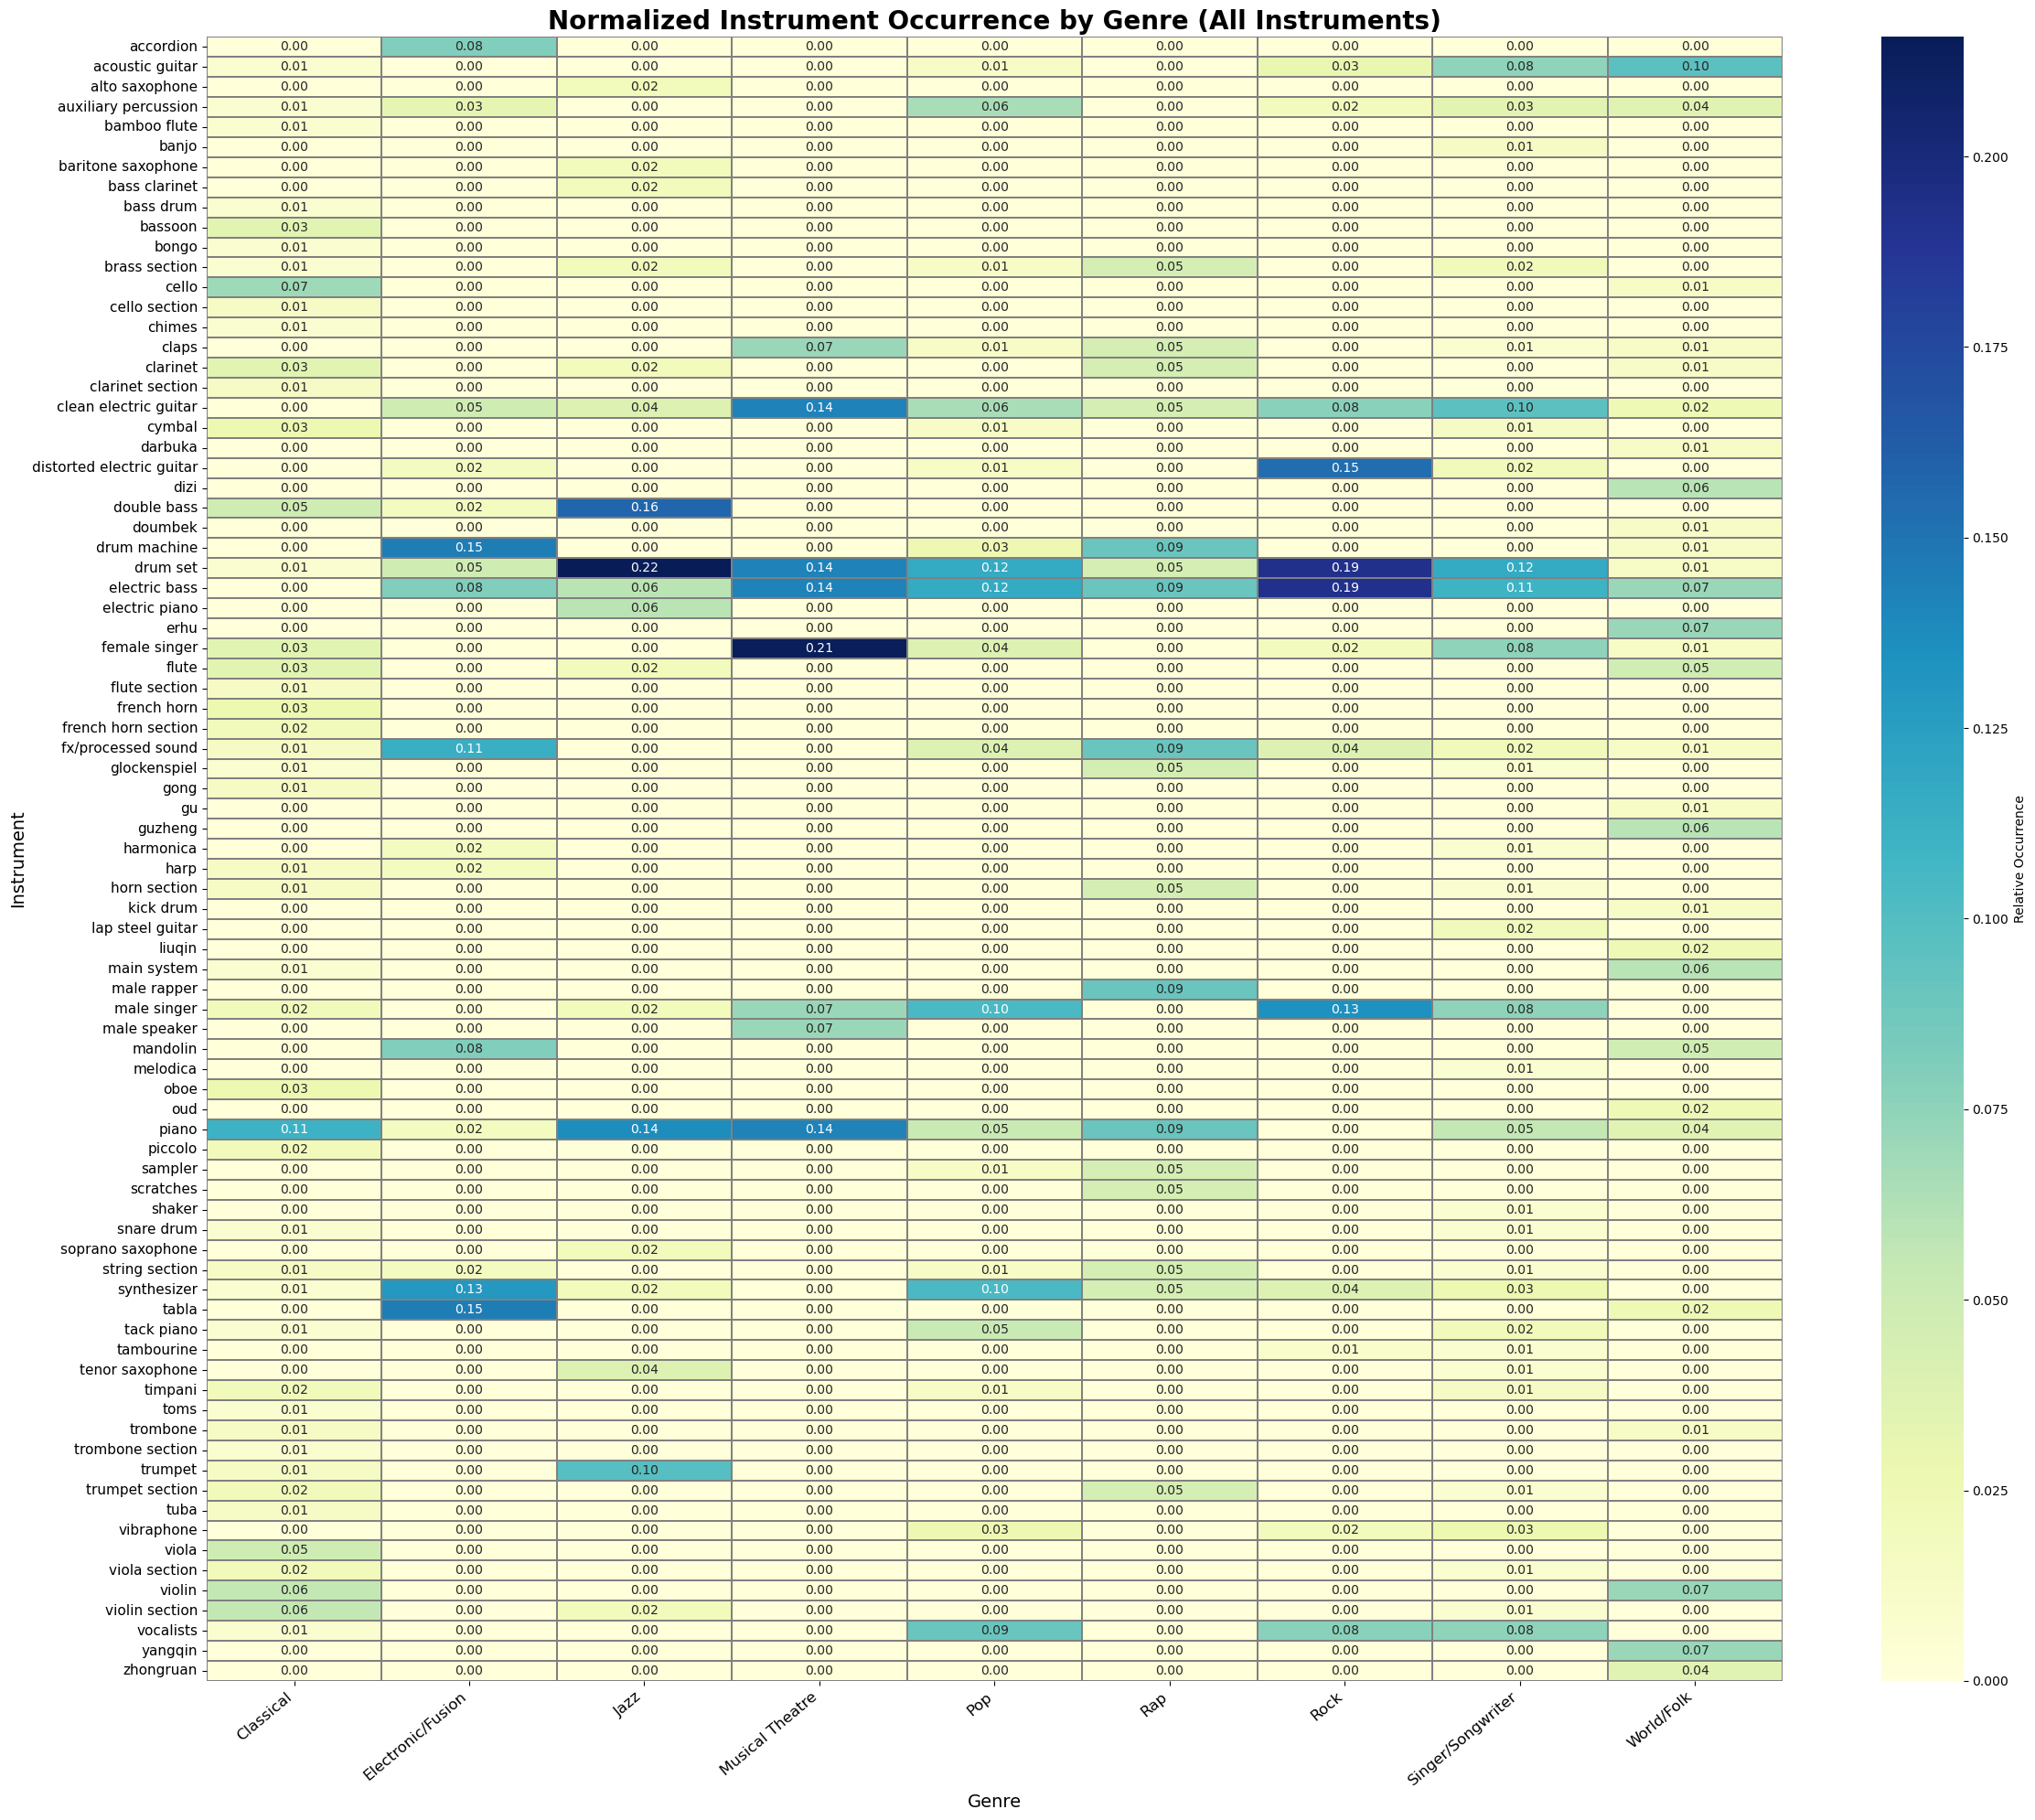

In [9]:
# Create a full matrix with all instruments and genres
all_instruments = sorted(all_instruments_set)
all_genres = sorted(df["genre"].unique())
matrix_full = pd.DataFrame(0, index=all_instruments, columns=all_genres)

observed = df_full.groupby("genre")[mlb.classes_].sum().T
matrix_full.loc[observed.index, observed.columns] = observed

# Normalize the matrix to show relative occurrence
normalized = matrix_full.div(matrix_full.sum(axis=0), axis=1)

# Plot
plt.figure(figsize=(24, 20))
sns.heatmap(
    normalized,
    cmap="YlGnBu",                 # elegant and readable colors
    linewidths=0.3,
    linecolor='gray',
    annot=True,                   # show numbers
    fmt=".2f",                    # two decimal places
    cbar_kws={'label': 'Relative Occurrence'},
    vmin=0,
    vmax=normalized.max().max()
)

plt.title("Normalized Instrument Occurrence by Genre (All Instruments)", fontsize=20, weight='bold')
plt.xlabel("Genre", fontsize=14)
plt.ylabel("Instrument", fontsize=14)
plt.xticks(rotation=40, ha='right', fontsize=12)
plt.yticks(fontsize=11)
plt.tight_layout()
plt.savefig("heatmap_all_82_pretty_full_annotated.png", dpi=300)
plt.show()

Analysis of the co-occurrence:

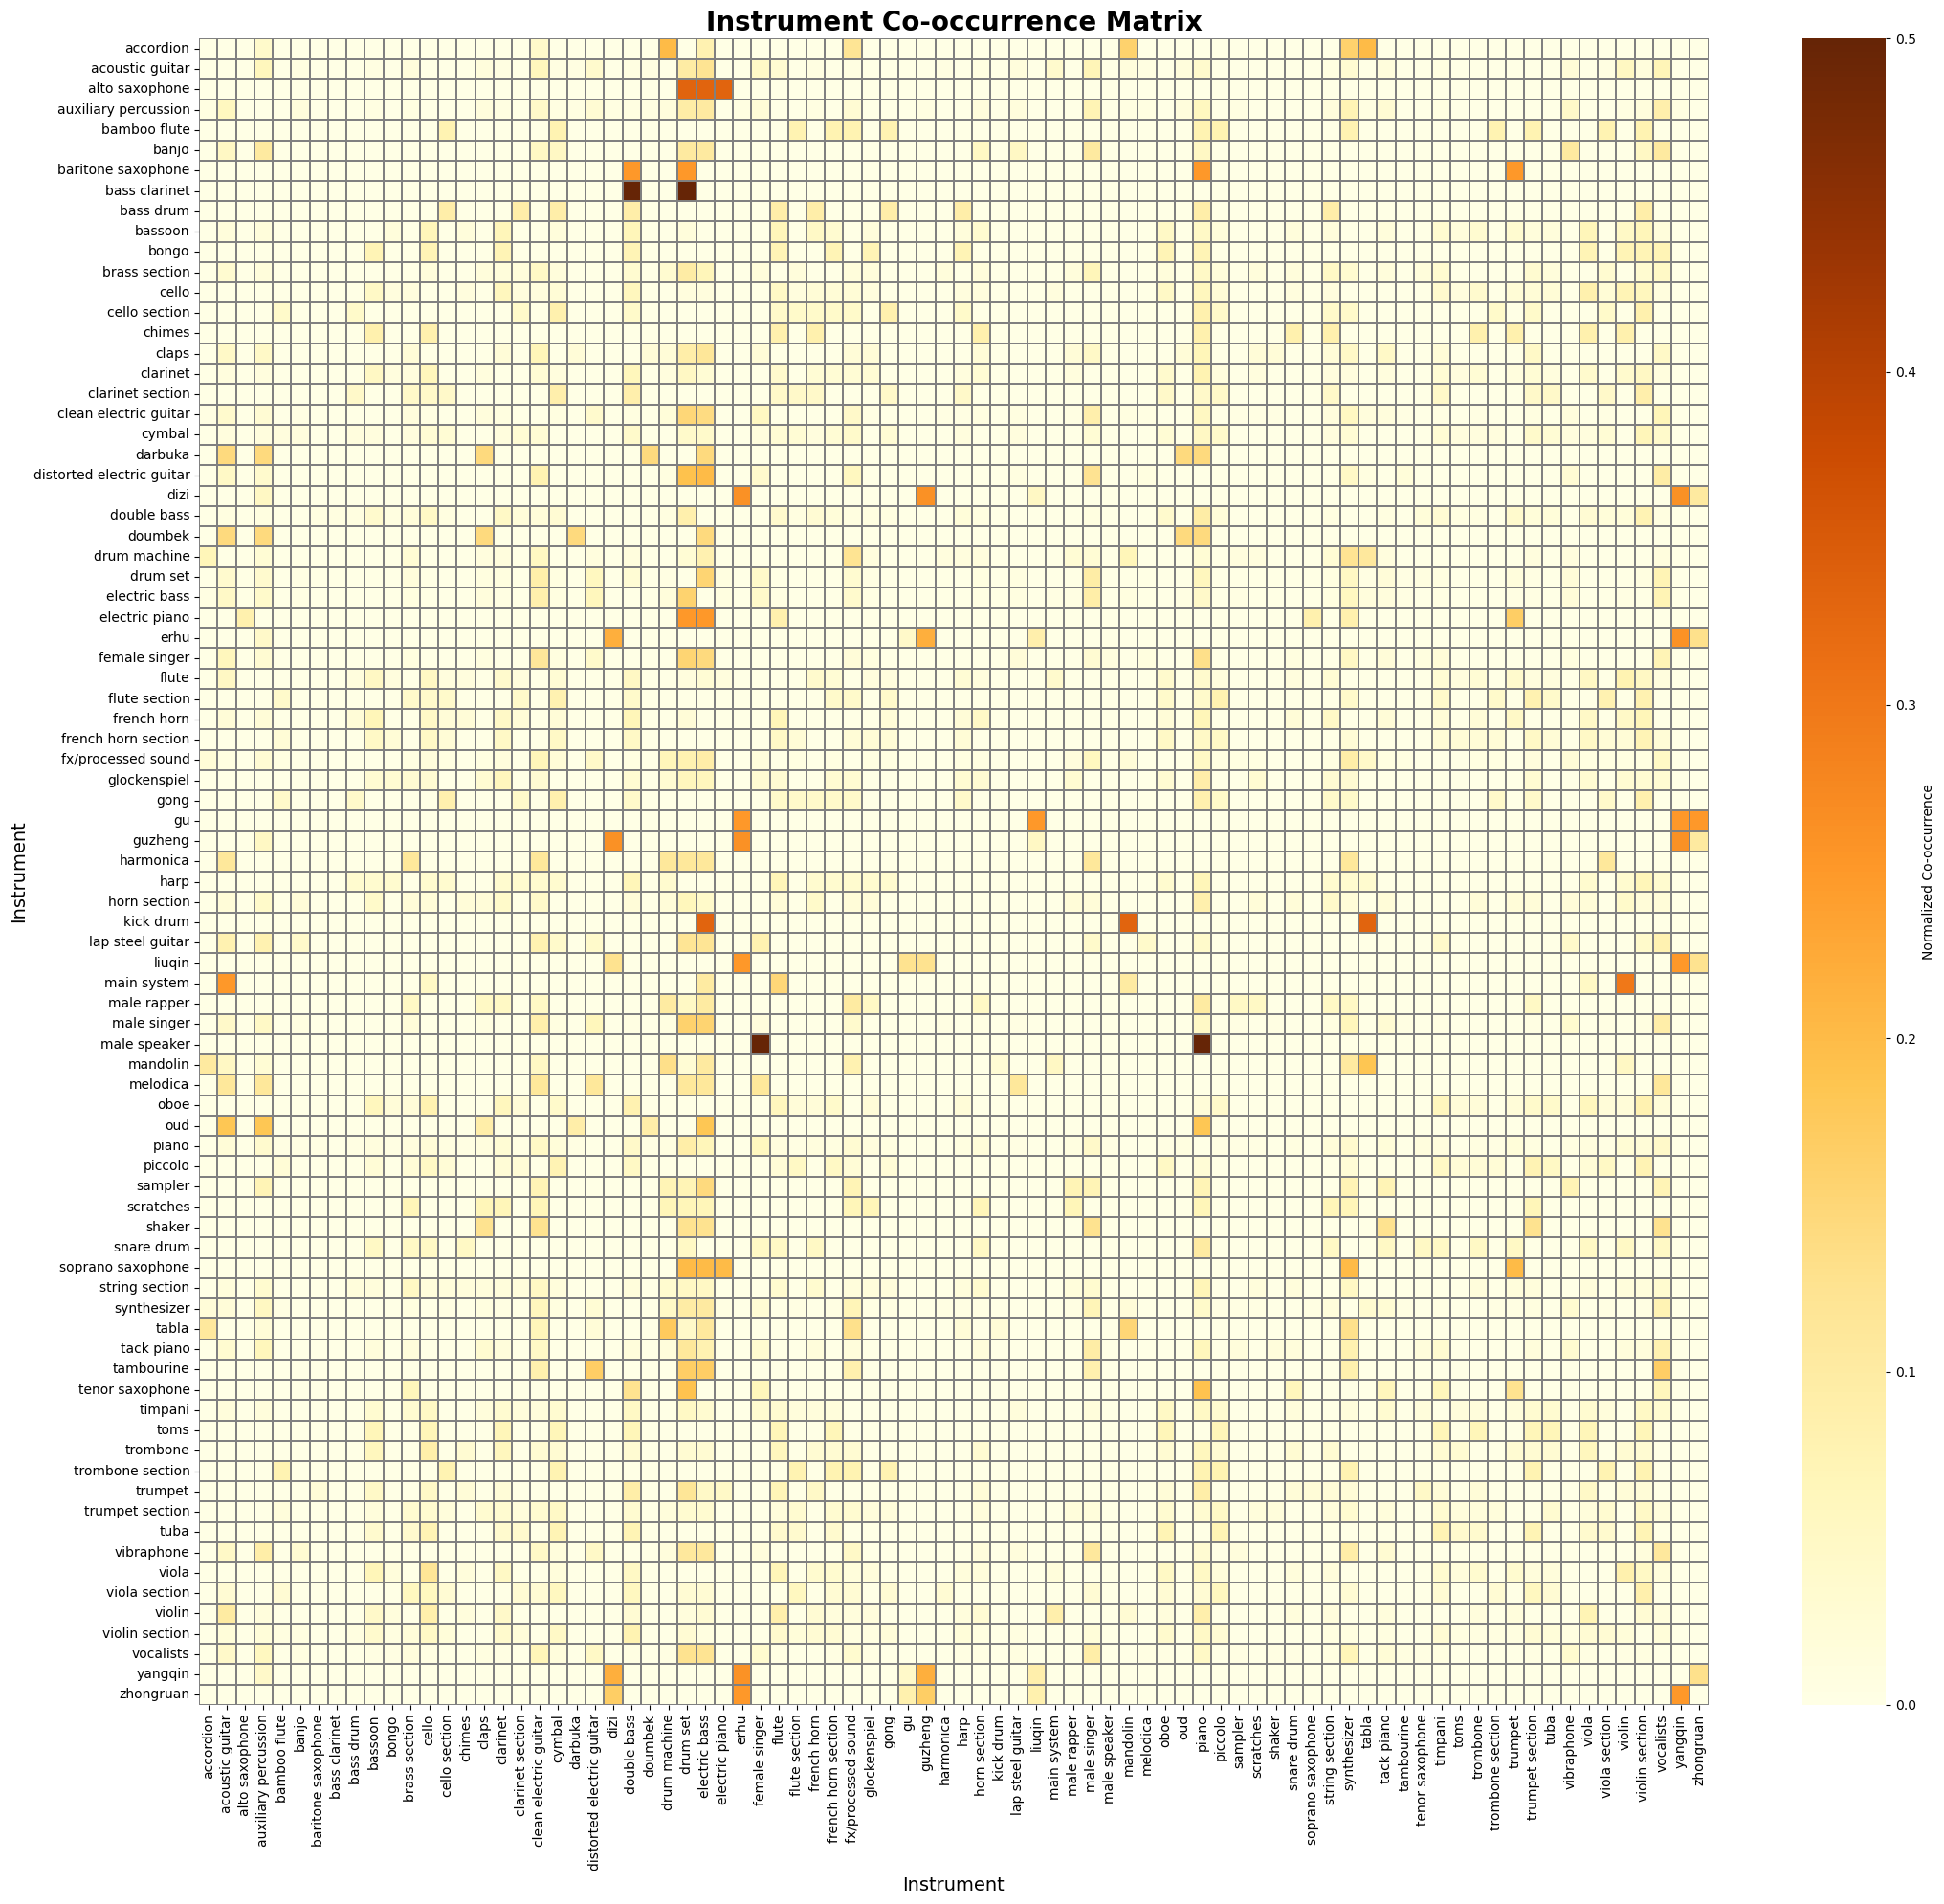

In [ ]:
# List of all instrument-instrument combinations for each track
co_occurrences = []

for instrument_list in instrument_per_song:
    # Generate all unique unordered pairs of instruments
    pairs = itertools.combinations(sorted(set(instrument_list)), 2)
    co_occurrences.extend(pairs)

# Count how many times each pair occurs
co_occurrence_counts = Counter(co_occurrences)

# Sorted list of all instruments to build a square matrix
all_instruments = sorted(all_instruments_set)

# Create square instrument × instrument matrix
co_matrix = pd.DataFrame(0, index=all_instruments, columns=all_instruments)

# Fill the matrix with co-occurrence counts
for (instr1, instr2), count in co_occurrence_counts.items():
    co_matrix.loc[instr1, instr2] = count
    co_matrix.loc[instr2, instr1] = count  # symmetric

# Normalize each row: how likely each instrument co-occurs with others (relative to its own total)
normalized_matrix = co_matrix.div(co_matrix.sum(axis=1), axis=0)

# Plot
plt.figure(figsize=(22, 20))
sns.heatmap(
    normalized_matrix,
    cmap="YlOrBr",
    linewidths=0.3,
    linecolor='gray',
    annot=False,
    cbar_kws={'label': 'Normalized Co-occurrence'}
)

plt.title("Instrument Co-occurrence Matrix", fontsize=20, weight='bold')
plt.xlabel("Instrument", fontsize=14)
plt.ylabel("Instrument", fontsize=14)
plt.xticks(rotation=90, fontsize=10)
plt.yticks(fontsize=10)
plt.tight_layout()
plt.savefig("co_occurrence_matrix.png", dpi=300)
plt.show()

Filtering the co-occurrence matrix:

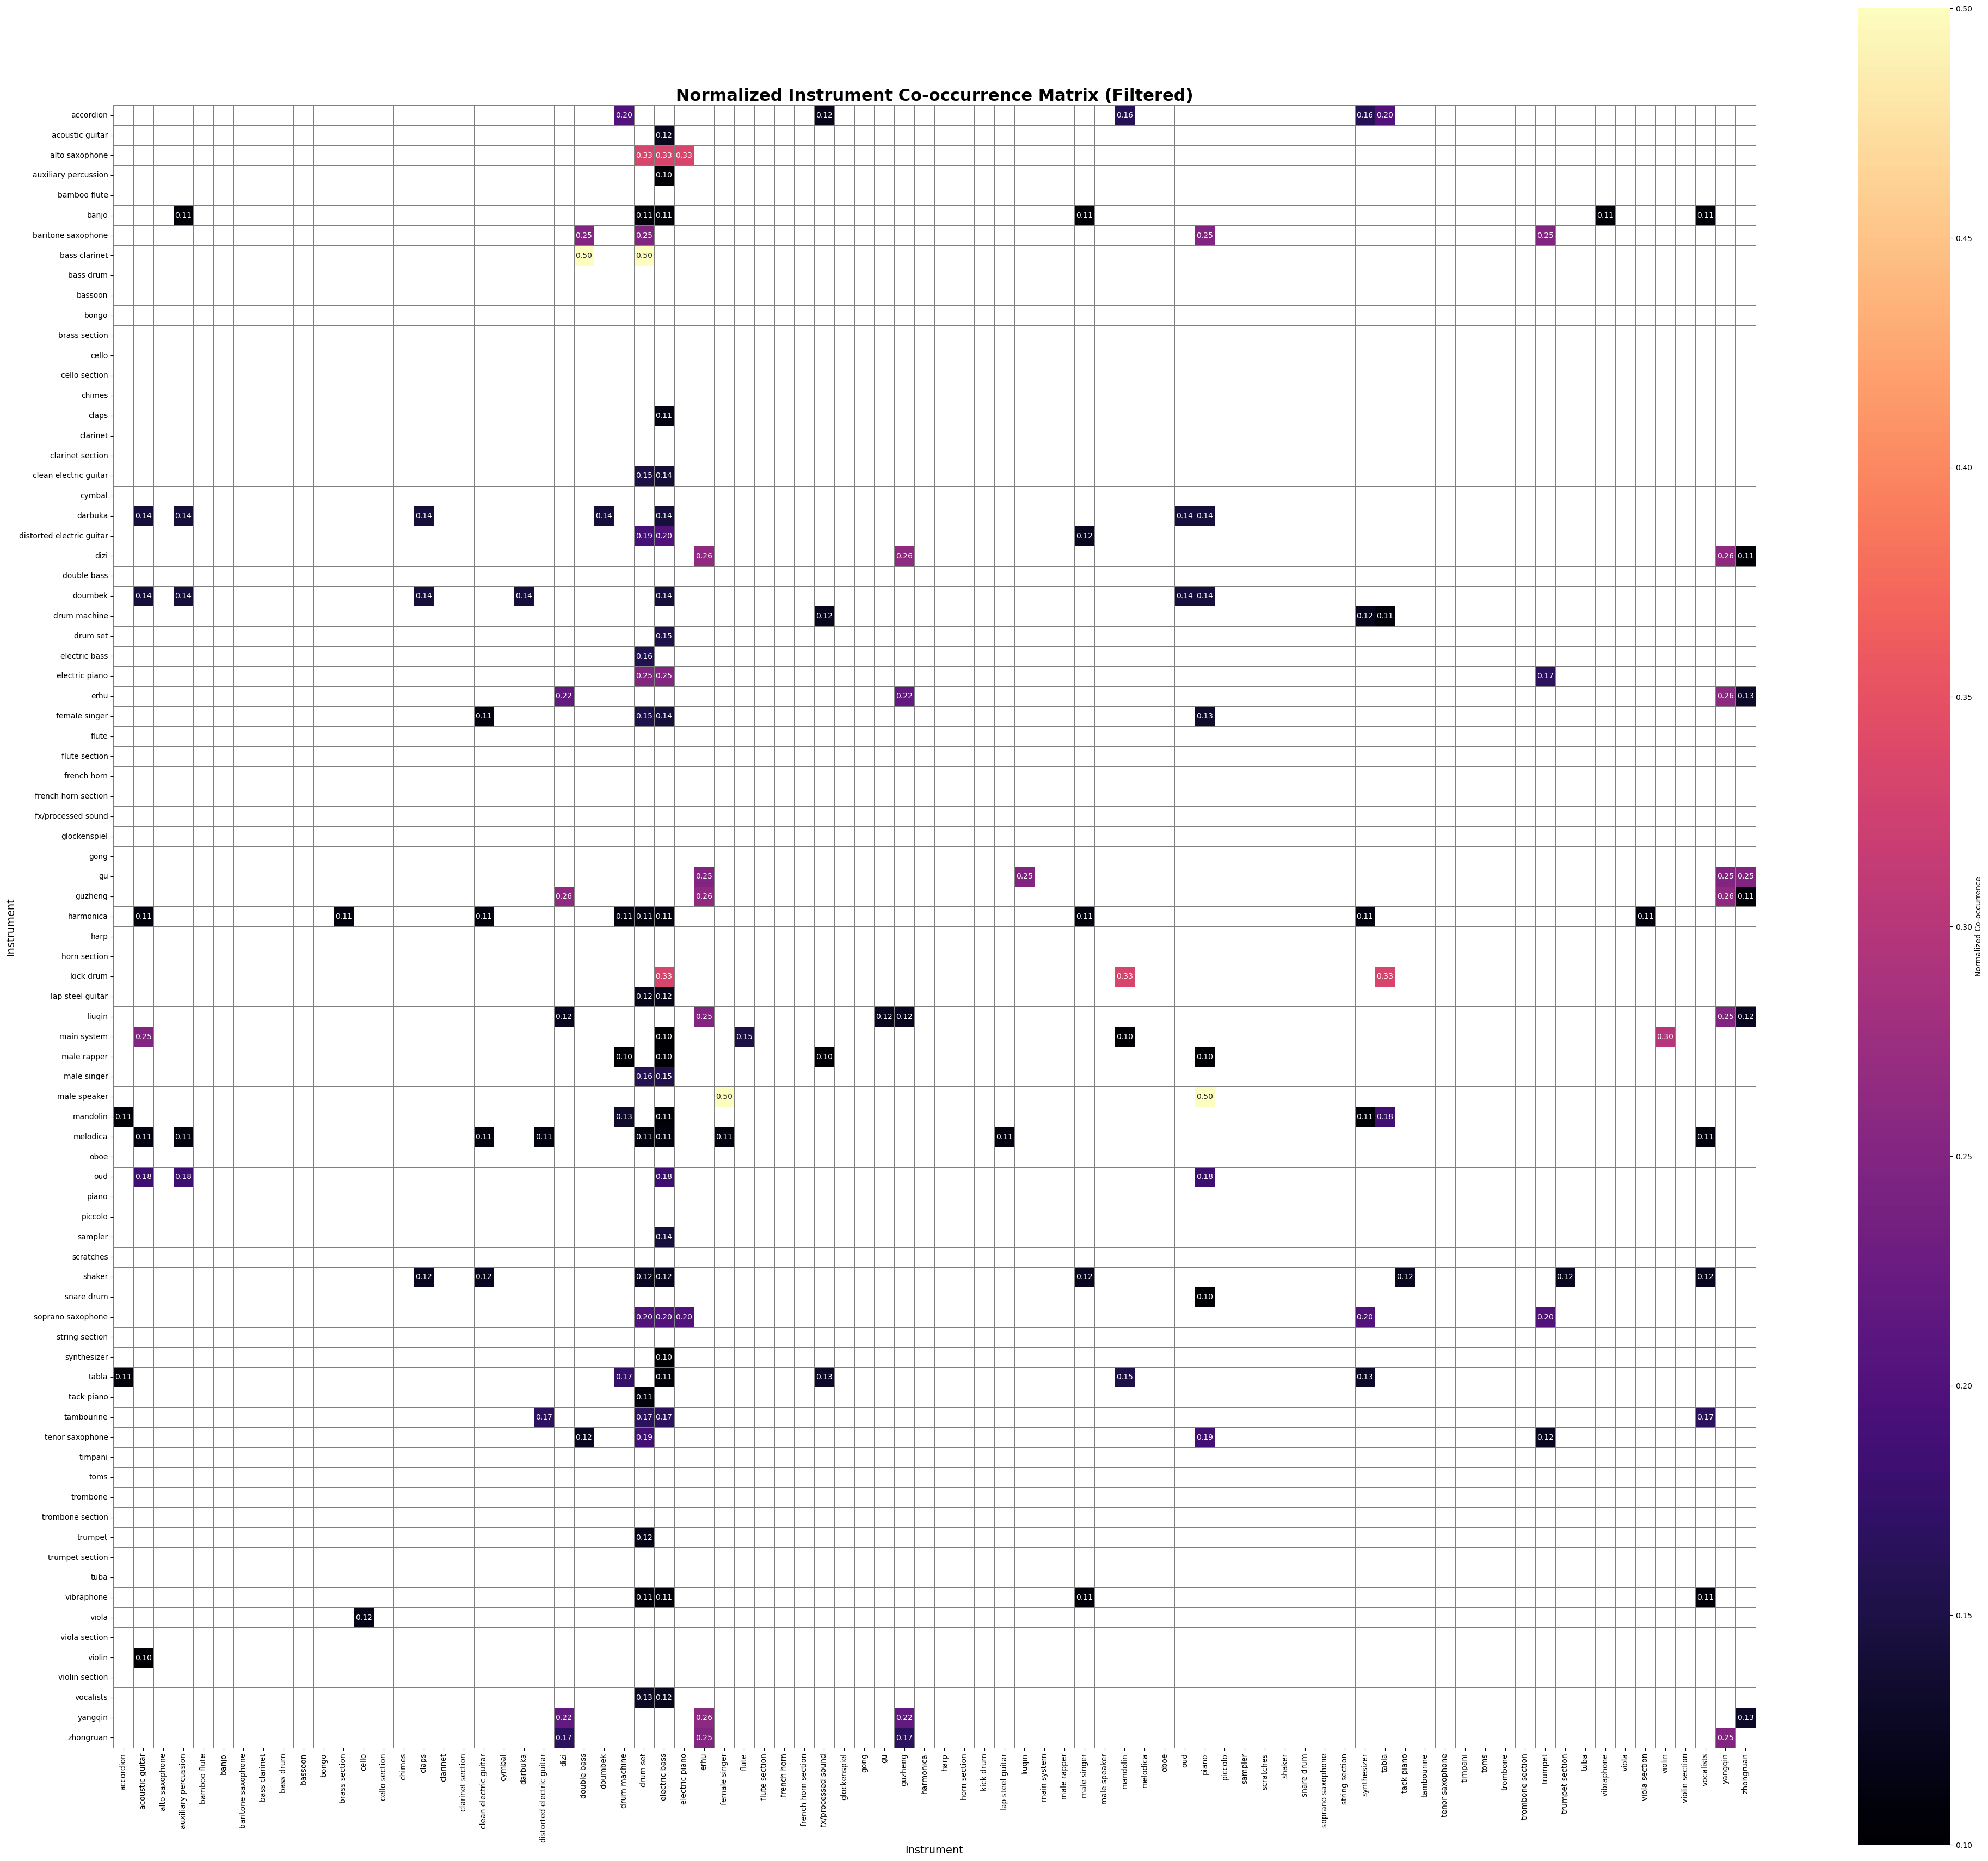

In [ ]:
# Optional filter: keep only instruments used at least N times
min_total_occurrence = 1  # N
used_instruments = co_matrix.sum(axis=1)[co_matrix.sum(axis=1) >= min_total_occurrence].index
co_matrix_filtered = co_matrix.loc[used_instruments, used_instruments]

# Normalize each row of the filtered matrix
normalized_filtered = co_matrix_filtered.div(co_matrix_filtered.sum(axis=1), axis=0)

# Plot
plt.figure(figsize=(40, 35)) 
mask = normalized_filtered < 0.1

sns.heatmap(
    normalized_filtered,
    cmap="magma",
    linewidths=0.5,
    linecolor='gray',
    annot=True,
    fmt=".2f",
    square=True,
    mask=mask,
    cbar_kws={'label': 'Normalized Co-occurrence'}
)

# Plot
plt.title("Normalized Instrument Co-occurrence Matrix (Filtered)", fontsize=22, weight='bold')
plt.xlabel("Instrument", fontsize=14)
plt.ylabel("Instrument", fontsize=14)
plt.xticks(rotation=90, fontsize=10)
plt.yticks(fontsize=10)
plt.tight_layout()
plt.savefig("co_occurrence_matrix_normalized_filtered.png", dpi=300)
plt.show()